In [62]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [82]:
# Semilla para repdoducibilidad
np.random.seed(33)
print("Semilla configurada: 33")

# Generamos 50 valores entre 0 y 10
# Generamos datos lineales con ruido gaussiano
x = np.linspace(0, 10, 50)

print("x ", x)

# Generamos y a partir de una recta y añadimos ruido gaussiano
y = 2 * x + 5 + np.random.normal(0, 3, size=len(x))
print("y ", y)

# Guardamos los datos en un dataframe
df = pd.DataFrame({"x":x,"y":y})
df.sample(5)

Semilla configurada: 33
x  [ 0.          0.20408163  0.40816327  0.6122449   0.81632653  1.02040816
  1.2244898   1.42857143  1.63265306  1.83673469  2.04081633  2.24489796
  2.44897959  2.65306122  2.85714286  3.06122449  3.26530612  3.46938776
  3.67346939  3.87755102  4.08163265  4.28571429  4.48979592  4.69387755
  4.89795918  5.10204082  5.30612245  5.51020408  5.71428571  5.91836735
  6.12244898  6.32653061  6.53061224  6.73469388  6.93877551  7.14285714
  7.34693878  7.55102041  7.75510204  7.95918367  8.16326531  8.36734694
  8.57142857  8.7755102   8.97959184  9.18367347  9.3877551   9.59183673
  9.79591837 10.        ]
y  [ 4.04343948  0.5992216   1.21067292  4.51328711  5.98246816  7.80543923
  7.00062978 13.88949058  7.97495365  9.94007437  8.40524796  7.57596664
  9.84910027 13.43877278  7.45964473  4.5046745   8.67695523 14.43769507
  9.34631428 13.78549027 17.80135609 15.64167141  7.84203174 15.39115559
 12.87154234 14.5365914  11.9211217  16.63795289 18.89268564 15.3553

,x,y
49,10.000000,29.463009
17,3.469388,14.437695
23,4.693878,15.391156
19,3.877551,13.785490
20,4.081633,17.801356


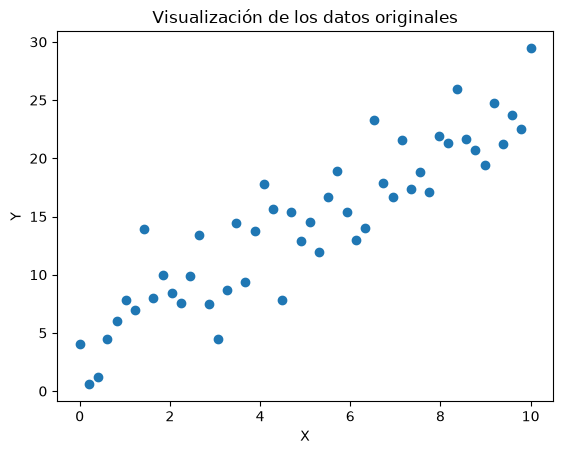

In [91]:
# Dibujamos los datos originales
plt.scatter(df["x"], df["y"])

# Etiquetas del gráfico
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Visualización de los datos originales")

# Mostramos el gráfico
plt.show()

In [90]:
X = sm.add_constant(df["x"])
print(X.head())

model = sm.OLS(df["y"], X).fit()

model.summary()

   const         x
0    1.0  0.000000
1    1.0  0.204082
2    1.0  0.408163
3    1.0  0.612245
4    1.0  0.816327


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.822
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     221.4
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           1.32e-19
Time:                        16:14:38   Log-Likelihood:                -123.29
No. Observations:                  50   AIC:                             250.6
Df Residuals:                      48   BIC:                             254.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.0097      0.810      4.949      0.000       2.381       5.639
x              2.0774      0.140     14.880      0.000       1.797       2.358
==============================================================================
Omnibus:                        0.871   Durbin-Watson:                   1.952
Prob(Omnibus):                  0.647   Jarque-Bera (JB):                0.897
Skew:                           0.290   Prob(JB):                        0.639
Kurtosis:                       2.695   Cond. No.                         11.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

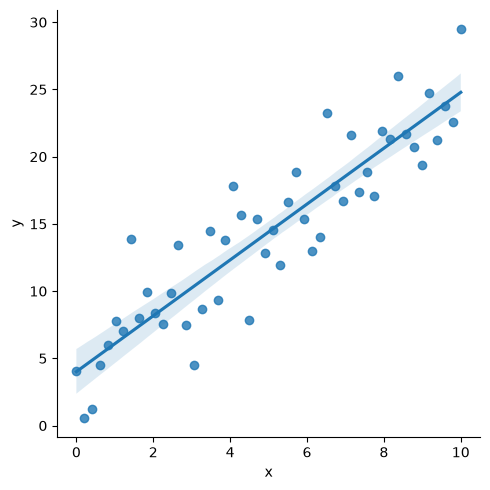

In [97]:
sns.lmplot(x="x",y="y", data=df, ci=95)

In [100]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(df[["x"]])

print("media ", X_scaled.mean())
print("desviacion estandar ", X_scaled.std())

df_scaled = df.copy()
df_scaled["x_escalada"] = X_scaled

df_scaled.head(10)

media  4.884981308350689e-17
desviacion estandar  1.0


,x,y,x_escalada
0,0.000000,4.043439,-1.697749
1,0.204082,0.599222,-1.628453
2,0.408163,1.210673,-1.559158
3,0.612245,4.513287,-1.489862
4,0.816327,5.982468,-1.420566
5,1.020408,7.805439,-1.351270
6,1.224490,7.000630,-1.281974
7,1.428571,13.889491,-1.212678
8,1.632653,7.974954,-1.143382
9,1.836735,9.940074,-1.074086
